<a href="https://colab.research.google.com/github/Aja2006/Unit_test/blob/main/Unit_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!

DATASET INFORMATION
Selected records: 10000
Remaining missing values: 0
Start time: 2006-12-16 17:24:00
End time: 2006-12-23 16:03:00

SEQUENCE INFORMATION
Training sequences: 7880
Testing sequences: 2000
Input shape: (7880, 120, 9)
Features: 9


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         5,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,921 (23.13 KB)

 Trainable params: 5,921 (23.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0070 - val_loss: 9.0394e-04
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0038 - val_loss: 6.8165e-04
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0036 - val_loss: 6.6613e-04
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0035 - val_loss: 6.5497e-04
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0034 - val_loss: 6.6825e-04
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0034 - val_loss: 6.7156e-04
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0033 - val_loss: 6.8283e-04
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0033 - val_loss: 6.6858e-04

FINAL MODEL EVALUATION

RESIDUAL LSTM
MAE:  0.4219 kW
RMSE: 0.7299 kW

PERSISTENCE BASELINE
MAE:  0.4092 kW
RMSE: 0.7361 kW

COMPARISON
Persistence baseline has equal or lower MAE.
Residual LSTM has lower RMSE.


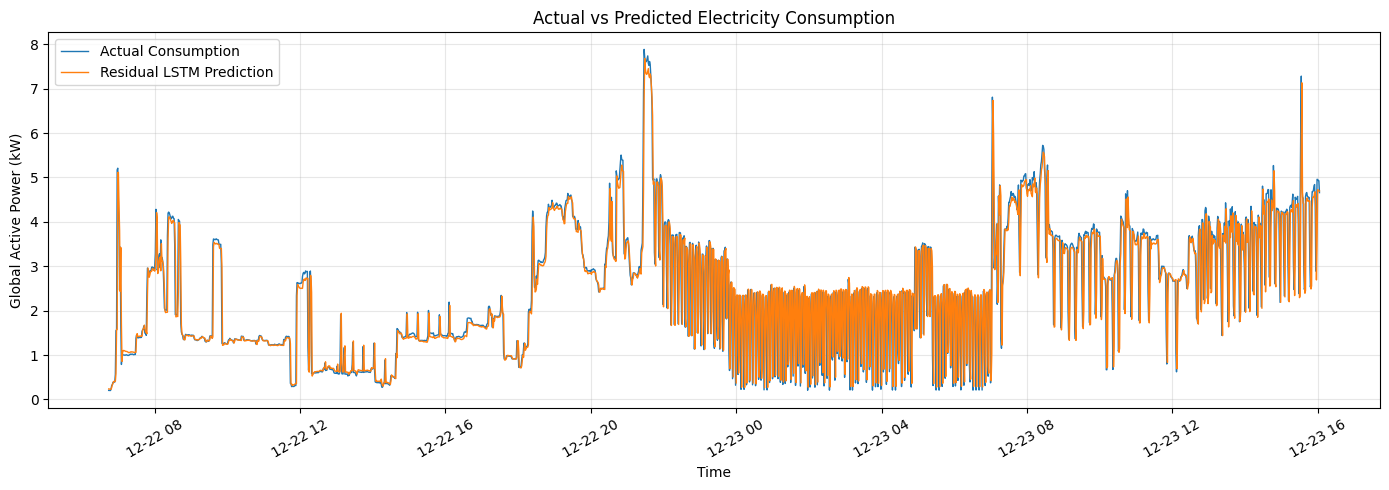

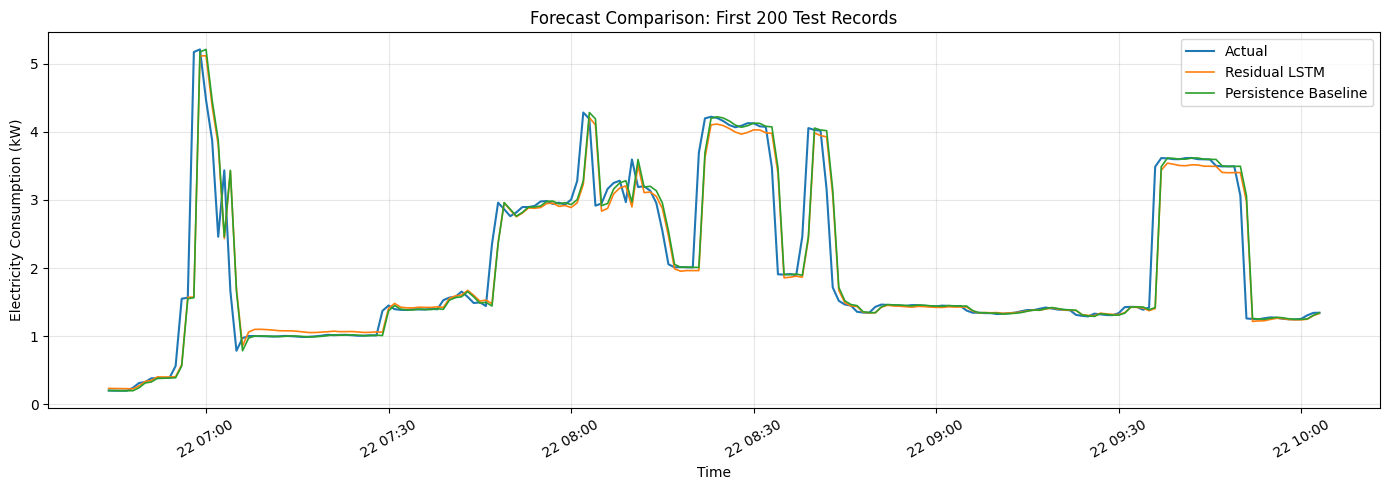

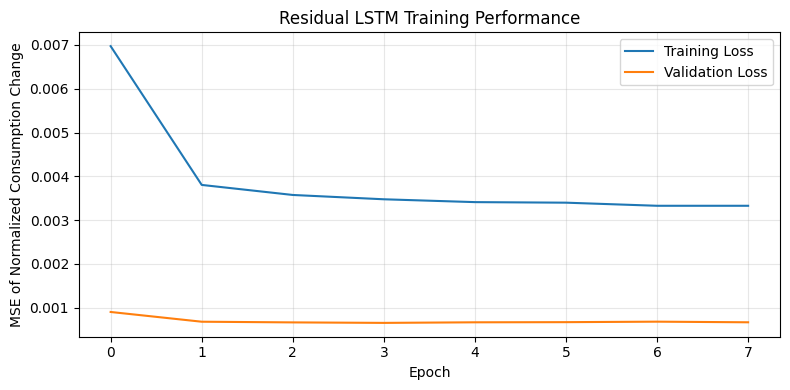


FIRST 10 UNSEEN TEST PREDICTIONS


,Time,Actual_kW,Residual_LSTM_kW,Persistence_kW,LSTM_Absolute_Error,Persistence_Absolute_Error
0,2006-12-22 06:44:00,0.204,0.236306,0.206,0.032306,0.002
1,2006-12-22 06:45:00,0.202,0.234343,0.204,0.032343,0.002
2,2006-12-22 06:46:00,0.202,0.232575,0.202,0.030575,0.000
3,2006-12-22 06:47:00,0.202,0.231740,0.202,0.029740,0.000
4,2006-12-22 06:48:00,0.246,0.230300,0.202,0.015700,0.044
5,2006-12-22 06:49:00,0.316,0.272420,0.246,0.043580,0.070
6,2006-12-22 06:50:00,0.330,0.337656,0.316,0.007656,0.014
7,2006-12-22 06:51:00,0.384,0.352935,0.330,0.031065,0.054
8,2006-12-22 06:52:00,0.386,0.404337,0.384,0.018337,0.002
9,2006-12-22 06:53:00,0.388,0.402874,0.386,0.014874,0.002



FILES SAVED SUCCESSFULLY
1. electricity_residual_lstm.keras
2. electricity_predictions.csv
3. actual_vs_predicted.png
4. forecast_comparison.png
5. training_loss.png
HOUSEHOLD ELECTRICITY PREDICTION
Enter the latest electricity measurements.

Enter date and time (YYYY-MM-DD HH:MM): 2006-12-22 06:43
Global active power (kW): 0.206
Global reactive power (kW): 0.034
Voltage (V): 241.5
Global intensity (A): 1.0
Sub-metering 1 (Wh): 0
Sub-metering 2 (Wh): 0
Sub-metering 3 (Wh): 1

PREDICTION RESULT
Latest input time: 2006-12-22 06:43:00
Input active power: 0.206 kW
Predicted next-minute active power: 0.238 kW
Forecast time: 2006-12-22 06:44:00


In [4]:

# ============================================================
# HOUSEHOLD ELECTRICITY CONSUMPTION FORECASTING
# Residual LSTM + Persistence Baseline
# ============================================================

# 1. IMPORT LIBRARIES
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported successfully!")

# ============================================================
# 2. LOAD DATASET
# ============================================================

file_path = "/content/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Electricity measurement features
features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["datetime"])
      .sort_values("datetime")
      .set_index("datetime")
)

# ============================================================
# 3. ADD TIME FEATURES
# ============================================================

hour = df.index.hour + df.index.minute / 60.0

df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

features += ["hour_sin", "hour_cos"]

# ============================================================
# 4. HANDLE MISSING VALUES AND SELECT RECORDS
# ============================================================

# Select 10,000 consecutive minute-level records BEFORE
# interpolation so the selection remains well-defined.
df = df[features].iloc[:10000].copy()

# Time-based interpolation for missing measurements
df[features] = df[features].interpolate(
    method="time",
    limit_direction="both"
)

# Drop any columns/records issues that still leave missing values
df = df.dropna(subset=features)

print("\nDATASET INFORMATION")
print("Selected records:", len(df))
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Start time:", df.index.min())
print("End time:", df.index.max())

if len(df) < 1000:
    raise ValueError("Not enough valid records to train the model.")

# ============================================================
# 5. NORMALIZE FEATURES
# ============================================================

target_col = "Global_active_power"
target_idx = features.index(target_col)

LOOKBACK = 120
TRAIN_END = int(len(df) * 0.80)

# Fit scaler using training period only
scaler = MinMaxScaler()
scaler.fit(df.iloc[:TRAIN_END][features])

scaled = scaler.transform(df[features])

# ============================================================
# 6. CREATE SEQUENCES
# ============================================================

X, y, positions = [], [], []

for i in range(LOOKBACK, len(scaled)):
    X.append(scaled[i - LOOKBACK:i])
    y.append(scaled[i, target_idx])
    positions.append(i)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
positions = np.asarray(positions)

# Chronological training/test split
train_mask = positions < TRAIN_END
test_mask = positions >= TRAIN_END

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

test_times = df.index[positions[test_mask]]

print("\nSEQUENCE INFORMATION")
print("Training sequences:", len(X_train))
print("Testing sequences:", len(X_test))
print("Input shape:", X_train.shape)
print("Features:", len(features))

# ============================================================
# 7. CREATE RESIDUAL TARGET
# ============================================================

# Predict the change from the most recent measurement
last_train = X_train[:, -1, target_idx]
last_test = X_test[:, -1, target_idx]

delta_train = y_train - last_train

# ============================================================
# 8. BUILD RESIDUAL LSTM MODEL
# ============================================================

model = Sequential([
    Input(shape=(LOOKBACK, len(features))),
    LSTM(32),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="mse"
)

model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# ============================================================
# 9. TRAIN THE MODEL
# ============================================================

history = model.fit(
    X_train,
    delta_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

# ============================================================
# 10. PREDICT UNSEEN TEST RECORDS
# ============================================================

# Predict normalized change in consumption
delta_pred = model.predict(X_test, verbose=0).ravel()

# Add predicted change to the latest normalized measurement
pred_scaled = last_test + delta_pred

# Convert normalized target values back to kW
power_range = (
    scaler.data_max_[target_idx]
    - scaler.data_min_[target_idx]
)

power_min = scaler.data_min_[target_idx]

y_actual = y_test * power_range + power_min
y_pred = pred_scaled * power_range + power_min

# ============================================================
# 11. PERSISTENCE BASELINE
# ============================================================

# Baseline predicts that the next measurement equals
# the most recent observed measurement.
baseline_pred = last_test * power_range + power_min

# ============================================================
# 12. CALCULATE MAE AND RMSE
# ============================================================

residual_mae = mean_absolute_error(y_actual, y_pred)
residual_rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

baseline_mae = mean_absolute_error(
    y_actual, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_actual, baseline_pred)
)

print("\n" + "=" * 50)
print("FINAL MODEL EVALUATION")
print("=" * 50)

print("\nRESIDUAL LSTM")
print(f"MAE:  {residual_mae:.4f} kW")
print(f"RMSE: {residual_rmse:.4f} kW")

print("\nPERSISTENCE BASELINE")
print(f"MAE:  {baseline_mae:.4f} kW")
print(f"RMSE: {baseline_rmse:.4f} kW")

print("\nCOMPARISON")

if residual_mae < baseline_mae:
    print("Residual LSTM has lower MAE.")
else:
    print("Persistence baseline has equal or lower MAE.")

if residual_rmse < baseline_rmse:
    print("Residual LSTM has lower RMSE.")
else:
    print("Persistence baseline has equal or lower RMSE.")

# ============================================================
# 13. ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    test_times,
    y_actual,
    label="Actual Consumption",
    linewidth=1
)

plt.plot(
    test_times,
    y_pred,
    label="Residual LSTM Prediction",
    linewidth=1
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

# ============================================================
# 14. COMPARE RESIDUAL LSTM WITH PERSISTENCE
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    test_times[:200],
    y_actual[:200],
    label="Actual",
    linewidth=1.5
)

plt.plot(
    test_times[:200],
    y_pred[:200],
    label="Residual LSTM",
    linewidth=1.2
)

plt.plot(
    test_times[:200],
    baseline_pred[:200],
    label="Persistence Baseline",
    linewidth=1.2
)

plt.title("Forecast Comparison: First 200 Test Records")
plt.xlabel("Time")
plt.ylabel("Electricity Consumption (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("forecast_comparison.png", dpi=150)
plt.show()

# ============================================================
# 15. TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 4))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Residual LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE of Normalized Consumption Change")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("training_loss.png", dpi=150)
plt.show()

# ============================================================
# 16. DISPLAY UNSEEN PREDICTIONS
# ============================================================

results = pd.DataFrame({
    "Time": test_times,
    "Actual_kW": y_actual,
    "Residual_LSTM_kW": y_pred,
    "Persistence_kW": baseline_pred,
    "LSTM_Absolute_Error": np.abs(y_actual - y_pred),
    "Persistence_Absolute_Error": np.abs(
        y_actual - baseline_pred
    )
})

print("\nFIRST 10 UNSEEN TEST PREDICTIONS")
display(results.head(10))

# ============================================================
# 17. SAVE MODEL AND RESULTS
# ============================================================

model.save("electricity_residual_lstm.keras")

results.to_csv(
    "electricity_predictions.csv",
    index=False
)

print("\nFILES SAVED SUCCESSFULLY")
print("1. electricity_residual_lstm.keras")
print("2. electricity_predictions.csv")
print("3. actual_vs_predicted.png")
print("4. forecast_comparison.png")
print("5. training_loss.png")


# ============================================================
# 18. ENTER INPUT AND PREDICT NEXT MINUTE CONSUMPTION
# For the trained Residual LSTM model
# ============================================================

print("HOUSEHOLD ELECTRICITY PREDICTION")
print("Enter the latest electricity measurements.\n")

# Enter timestamp for your latest measurement
input_time = pd.to_datetime(
    input("Enter date and time (YYYY-MM-DD HH:MM): ")
)

# Enter the seven electricity features
user_reading = {}

user_reading["Global_active_power"] = float(
    input("Global active power (kW): ")
)
user_reading["Global_reactive_power"] = float(
    input("Global reactive power (kW): ")
)
user_reading["Voltage"] = float(
    input("Voltage (V): ")
)
user_reading["Global_intensity"] = float(
    input("Global intensity (A): ")
)
user_reading["Sub_metering_1"] = float(
    input("Sub-metering 1 (Wh): ")
)
user_reading["Sub_metering_2"] = float(
    input("Sub-metering 2 (Wh): ")
)
user_reading["Sub_metering_3"] = float(
    input("Sub-metering 3 (Wh): ")
)

# Add time-of-day features
hour_value = input_time.hour + input_time.minute / 60.0

user_reading["hour_sin"] = np.sin(
    2 * np.pi * hour_value / 24
)
user_reading["hour_cos"] = np.cos(
    2 * np.pi * hour_value / 24
)

# Validate input
new_row = pd.DataFrame(
    [user_reading],
    index=[input_time]
)
new_row = new_row[features]

if not np.isfinite(new_row.to_numpy()).all():
    raise ValueError("All input values must be finite numbers.")

if (new_row["Global_active_power"] < 0).any():
    raise ValueError("Active power cannot be negative.")

# Get the preceding 119 measurements from the dataset.
# The entered row is treated as the latest measurement.
previous_rows = df.loc[df.index < input_time].tail(LOOKBACK - 1)

if len(previous_rows) < LOOKBACK - 1:
    raise ValueError(
        "Not enough historical records before this timestamp. "
        "Use a timestamp later than the available dataset history."
    )

# Build the 120-step input sequence
input_history = pd.concat([previous_rows, new_row])
input_history = input_history[features]

# Normalize using the scaler already fitted during training
input_scaled = scaler.transform(input_history)

X_input = input_scaled.reshape(
    1, LOOKBACK, len(features)
).astype(np.float32)

# Predict the change in active power
predicted_change_scaled = model.predict(
    X_input, verbose=0
)[0, 0]

# Residual LSTM: latest value + predicted change
latest_scaled_power = input_scaled[-1, target_idx]

predicted_scaled_power = (
    latest_scaled_power + predicted_change_scaled
)

# Convert predicted value back to kW
power_range = (
    scaler.data_max_[target_idx]
    - scaler.data_min_[target_idx]
)
power_min = scaler.data_min_[target_idx]

predicted_power_kw = (
    predicted_scaled_power * power_range + power_min
)

# Active power cannot be negative
predicted_power_kw = max(0.0, predicted_power_kw)

print("\n" + "=" * 40)
print("PREDICTION RESULT")
print("=" * 40)
print("Latest input time:", input_time)
print("Input active power:",
      user_reading["Global_active_power"], "kW")
print("Predicted next-minute active power:",
      round(float(predicted_power_kw), 3), "kW")
print("Forecast time:", input_time + pd.Timedelta(minutes=1))
print("=" * 40)

